In [12]:
!pip install rdkit


In [13]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors,AllChem
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [14]:
def compute_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol:
      return{
          'MolWt': Descriptors.MolWt(mol),
          'MolLogP': Descriptors.MolLogP(mol),
          'NumHDonors': Descriptors.NumHDonors(mol),
          'NumHAcceptors': Descriptors.NumHAcceptors(mol),

      }
    else:
      return None




In [15]:
df=pd.read_csv('delaney-processed.csv').drop_duplicates().dropna()
df.head()

,Compound ID,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-1.33,c1ccsc1


In [16]:
df.isnull().sum()

,0
Compound ID,0
measured log solubility in mols per litre,0
smiles,0


In [17]:
descriptors=df['smiles'].apply(compute_descriptors).dropna()
descriptors.head()

,smiles
0,"{'MolWt': 457.4320000000001, 'MolLogP': -3.108..."
1,"{'MolWt': 201.22500000000002, 'MolLogP': 2.840..."
2,"{'MolWt': 152.237, 'MolLogP': 2.87800000000000..."
3,"{'MolWt': 278.354, 'MolLogP': 6.29940000000000..."
4,"{'MolWt': 84.14299999999999, 'MolLogP': 1.7480..."


In [18]:
features=pd.DataFrame(descriptors.tolist())
features.head()

,MolWt,MolLogP,NumHDonors,NumHAcceptors
0,457.432,-3.10802,7,12
1,201.225,2.84032,1,2
2,152.237,2.87800,0,1
3,278.354,6.29940,0,0
4,84.143,1.74810,0,1


In [19]:
x=features
y=df['measured log solubility in mols per litre']

In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)


In [21]:
paramm_grid={
    'n_estimators':[100,200,300],
    'max_depth':[None,10,20,30],
    'min_samples_split':[2,5,10]
}

In [22]:
grid_search=GridSearchCV(RandomForestRegressor(random_state=42),paramm_grid,cv=5)
grid_search.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42),
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]})

In [23]:
best_model=grid_search.best_estimator_
y_pred=best_model.predict(x_test)
r2=r2_score(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(f'R2 Score: {r2}')
print(f'MSE: {mse}')

R2 Score: 0.8431348762807834
MSE: 0.7414706141746863


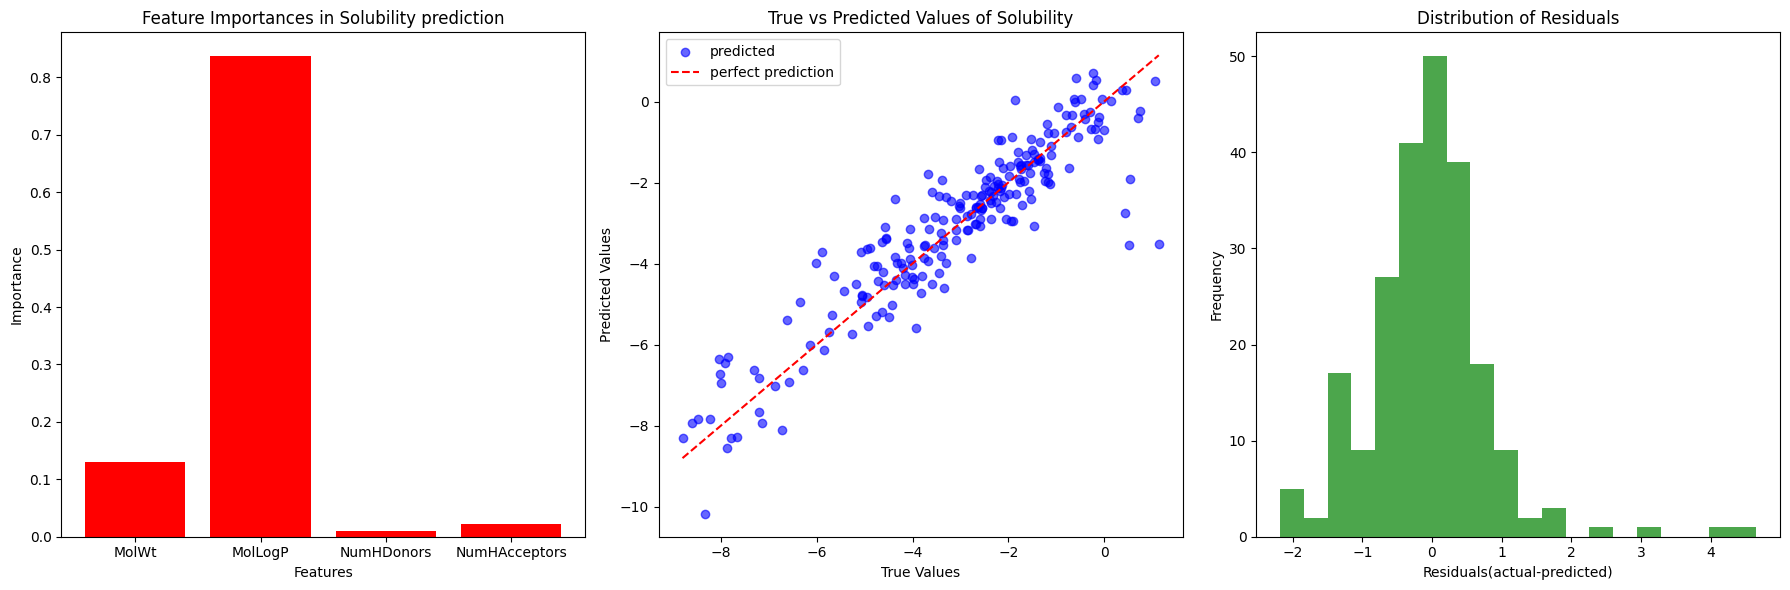

In [24]:
fig ,axes=plt.subplots(1,3,figsize=(18,6))
axes[0].bar(x.columns,best_model.feature_importances_,color='red')
axes[0].set_xlabel('Features')
axes[0].set_ylabel('Importance')
axes[0].set_title('Feature Importances in Solubility prediction')

axes[1].scatter(y_test,y_pred,color='blue',alpha=0.6,label='predicted')
axes[1].plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--',label='perfect prediction')
axes[1].set_xlabel('True Values')
axes[1].set_ylabel('Predicted Values')
axes[1].set_title('True vs Predicted Values of Solubility')
axes[1].legend()

residuals=y_test-y_pred
axes[2].hist(residuals,bins=20,color='green',alpha=0.7)
axes[2].set_title('Distribution of Residuals')
axes[2].set_xlabel('Residuals(actual-predicted)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()
